<a href="https://colab.research.google.com/github/Neha-984055/Deep-Learning/blob/main/dl_skill_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip install ultralytics -q


In [2]:

from google.colab import files

uploaded = files.upload()

image_path = next(iter(uploaded))

print("Image uploaded successfully!")
print("File name:", image_path)


Saving Annotated City Traffic Detection Scene.png to Annotated City Traffic Detection Scene.png
Image uploaded successfully!
File name: Annotated City Traffic Detection Scene.png


In [3]:

from ultralytics import YOLO

# Load a pretrained YOLO model
model = YOLO("yolov8n.pt")

print("YOLO model loaded successfully!")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLO model loaded successfully!


In [4]:

results = model.predict(
    source=image_path,
    imgsz=640,
    conf=0.25,
    verbose=False
)

print("Image processed successfully!")
print("Model prediction completed!")


Image processed successfully!
Model prediction completed!


In [5]:

import json

result = results[0]

detections = []

for box in result.boxes:
    class_id = int(box.cls[0])
    object_name = model.names[class_id]
    confidence = float(box.conf[0])

    detections.append({
        "object": object_name,
        "confidence": round(confidence, 2)
    })

response = {
    "status": "success",
    "image": image_path,
    "total_objects": len(detections),
    "detections": detections
}

print(json.dumps(response, indent=4))


{
    "status": "success",
    "image": "Annotated City Traffic Detection Scene.png",
    "total_objects": 12,
    "detections": [
        {
            "object": "bus",
            "confidence": 0.92
        },
        {
            "object": "person",
            "confidence": 0.91
        },
        {
            "object": "car",
            "confidence": 0.89
        },
        {
            "object": "person",
            "confidence": 0.86
        },
        {
            "object": "person",
            "confidence": 0.85
        },
        {
            "object": "motorcycle",
            "confidence": 0.64
        },
        {
            "object": "car",
            "confidence": 0.58
        },
        {
            "object": "truck",
            "confidence": 0.57
        },
        {
            "object": "person",
            "confidence": 0.51
        },
        {
            "object": "backpack",
            "confidence": 0.42
        },
        {
            "object": "

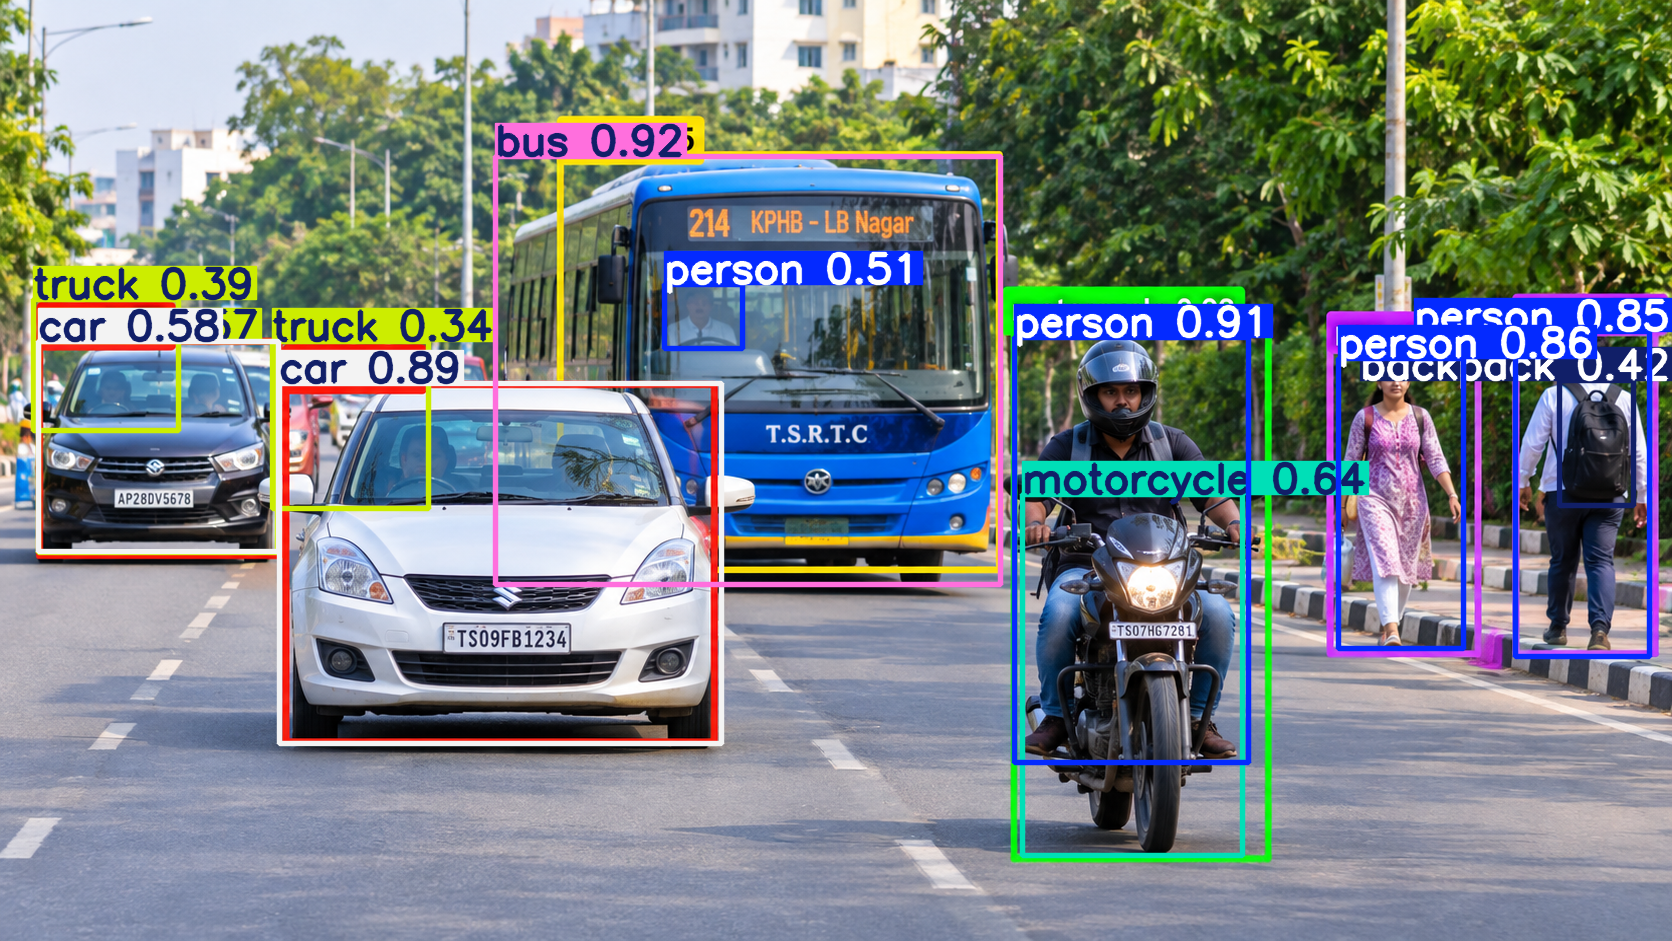

In [6]:

from PIL import Image
from IPython.display import display

annotated_image = result.plot()

display(Image.fromarray(annotated_image[:, :, ::-1]))


In [7]:
{
    "status": "success",
    "image": "traffic.jpg",
    "total_objects": 3,
    "detections": [
        {
            "object": "car",
            "confidence": 0.94
        },
        {
            "object": "bus",
            "confidence": 0.89
        },
        {
            "object": "motorcycle",
            "confidence": 0.91
        }
    ]
}

{'status': 'success',
 'image': 'traffic.jpg',
 'total_objects': 3,
 'detections': [{'object': 'car', 'confidence': 0.94},
  {'object': 'bus', 'confidence': 0.89},
  {'object': 'motorcycle', 'confidence': 0.91}]}